#### Find the number of movies that were released in theatres each year:

load data

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# go level up to data/
df = pd.read_csv("../../data/movies_data.csv")

df.head()

,movie_id,movie_title,movie_info,rating,genre,directors,in_theaters_date,on_streaming_date,runtime_in_minutes,critic_rating,critic_count,audience_rating,audience_count
0,1,Percy Jackson & the Olympians: The Lightning T...,A teenager discovers he's the descendant of a ...,PG,"Action & Adventure, Comedy, Drama, Science Fic...",Chris Columbus,2010-02-12,2010-06-29,83.0,49,144,53.0,254287.0
1,2,Please Give,Kate has a lot on her mind. There's the ethics...,R,Comedy,Nicole Holofcener,2010-04-30,2010-10-19,90.0,86,140,64.0,11567.0
2,3,10,Blake Edwards' 10 stars Dudley Moore as George...,R,"Comedy, Romance",Blake Edwards,1979-10-05,1997-08-27,118.0,68,22,53.0,14670.0
3,4,12 Angry Men (Twelve Angry Men),"A Puerto Rican youth is on trial for murder, a...",NaN,"Classics, Drama",Sidney Lumet,2057-04-13,2001-03-06,95.0,100,51,97.0,105000.0
4,5,"20,000 Leagues Under The Sea","This 1954 Disney version of Jules Verne's 20,0...",G,"Action & Adventure, Drama, Kids & Family",Richard Fleischer,2054-01-01,2003-05-20,127.0,89,27,74.0,68860.0


In [7]:
df.columns

Index(['movie_id', 'movie_title', 'movie_info', 'rating', 'genre', 'directors',
       'in_theaters_date', 'on_streaming_date', 'runtime_in_minutes',
       'critic_rating', 'critic_count', 'audience_rating', 'audience_count'],
      dtype='object')

In [17]:
df.shape

(16638, 14)

Erroneous values in the data

A few movies had theatre release years far in the future (e.g., 2050-plus) as well as some missing dates. These are not plausible release years, so I treated them as data errors. 

In [26]:
# convert to datetime and extract year from in_theaters_date
df["release_year"] = (
    pd.to_datetime(df["in_theaters_date"], errors="coerce")
      .dt.year
)

# drop obviously bad years, e.g. before 1900 or after 2025
min_year, max_year = 1900, 2025
mask_bad = (
    df["release_year"].isna()
    | (df["release_year"] < min_year)
    | (df["release_year"] > max_year)
)
df_clean = df.loc[~mask_bad].copy()
df_clean["release_year"] = df_clean["release_year"].astype(int)
df_clean.shape

(14294, 14)

I converted in_theaters_date to a datetime, extracted the year, and then flagged any records with missing years or years outside a reasonable range (1900–2025) as erroneous and removed them before counting movies per year.

In [27]:
# count movies per year
movies_per_year = (
    df_clean["release_year"]
    .value_counts()
    .sort_index()
)

movies_per_year.head()

release_year
1970    62
1971    67
1972    70
1973    81
1974    63
Name: count, dtype: int64

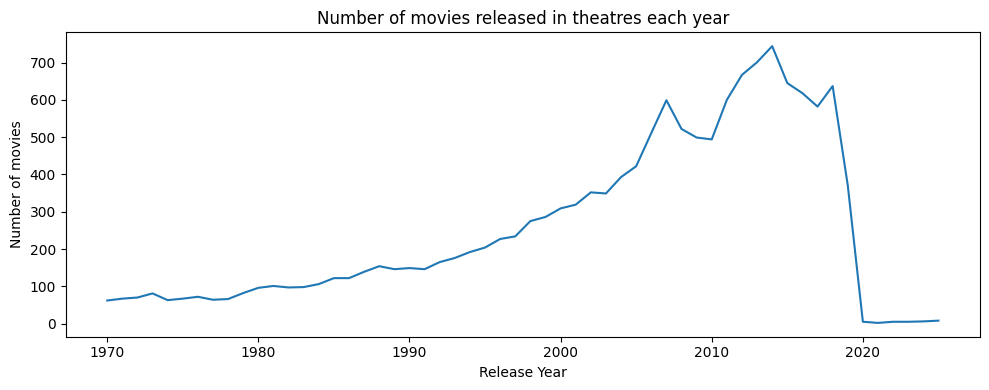

In [28]:
# visualize
plt.figure(figsize=(10,4))
movies_per_year.plot()
plt.xlabel("Release Year")
plt.ylabel("Number of movies")
plt.title("Number of movies released in theatres each year")
plt.tight_layout()
plt.show()

The plot shows a steady increase in the number of theatrical releases from the 1970s (around 60–80 movies per year) through the 1990s and 2000s, reaching a peak of roughly 700+ movies per year in the mid-2010s. After that peak there is a decline, with a very sharp drop around 2020, followed by only a small number of movies in the most recent years. This suggests both a real slowdown around 2020 (likely related to COVID-19) and also that the dataset may be less complete for the very latest years.

Assumptions and fixes going forward

Going forward, I assume that: 

in_theaters_date is the correct reference point for “released in theatres,”

movies with missing or implausible theatre years (outside 1900–2025) are data errors and should be excluded, and

the remaining movies form a reasonable sample for modeling critic ratings.

Based on these assumptions, I will keep only rows with a valid release_year in the chosen range and drop the erroneous records. For any downstream features that depend on time (e.g., release year or movie age), I will use this cleaned release_year column so that outliers and bad dates do not distort the analysis or model.

#### Looking only at movies that were released in theatres before 2010:

In [29]:
# movies released in theatres before 2010
df_pre2010 = df_clean[df_clean["release_year"] < 2010].copy()
df_pre2010.shape

(8204, 14)

Find the 5 highest rated movies by critics (critic_rating)

In [30]:
# 5 highest rated by critics
top5_critics = (
    df_pre2010
    .sort_values("critic_rating", ascending=False)
    [["movie_title", "release_year", "critic_rating"]]
    .head(5)
)
print("Top 5 movies by critic_rating (before 2010):")
top5_critics

Top 5 movies by critic_rating (before 2010):


,movie_title,release_year,critic_rating
8449,Men at Work,2006,100
8683,Kwik Stop,2001,100
15205,36 quai des orfevres,2005,100
13499,Taxi to the Dark Side,2007,100
8685,The Confession,1970,100


Find the 5 highest rated movies by the general audience (audience_rating)

In [31]:
# 5 highest rated by audience
top5_audience = (
    df_pre2010
    .sort_values("audience_rating", ascending=False)
    [["movie_title", "release_year", "audience_rating"]]
    .head(5)
)
print("Top 5 movies by audience_rating (before 2010):")
top5_audience

Top 5 movies by audience_rating (before 2010):


,movie_title,release_year,audience_rating
222,Prima Ballerina,2009,100.0
1846,Ice People,2008,100.0
1283,La Ciudad (The City),1998,100.0
3229,Been Rich All My Life,2006,100.0
12463,The Shawshank Redemption,1994,98.0
